# Speaker diarization: turns, speakers, and concentration

This notebook summarizes the 2026 speaker-diarization results at two levels:

- **Conversation level:** number of diarization speaker turns, number of detected speakers, total detected speech, and concentration measures.
- **Speaker level:** each anonymous speaker label's speaking duration, turn count, share, and within-conversation rank.

A diarization *speaker turn* is distinct from a transcript text cue. Empty and punctuation-only text cues are excluded from text and topic counts, while speaker concentration is measured from diarization turns and detected speaking duration. Speaker labels are local to each conversation: `SPEAKER_00` in two files does not imply the same person.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from arvamusfestivali_transcripts.diarization_analysis import (
    load_conversation_summaries,
    primary_topic_summary,
)
from arvamusfestivali_transcripts.text_quality import has_meaningful_text

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## Load and validate the results

The path lookup works whether the notebook is launched from the repository root or from `notebooks/`. Only numeric `*.json` episode files are loaded.

In [2]:
project_root = Path.cwd().resolve()
if not (project_root / "data/diarization/2026").exists():
    project_root = project_root.parent
data_dir = project_root / "data/diarization/2026"
if not data_dir.exists():
    raise FileNotFoundError(f"Diarization directory not found: {data_dir}")

conversation_rows, speaker_rows = load_conversation_summaries(data_dir)
conversations = pd.DataFrame(conversation_rows).sort_values("episode_id").reset_index(drop=True)
speakers = pd.DataFrame(speaker_rows).sort_values(["episode_id", "speaker_rank"]).reset_index(drop=True)

print(f"Loaded {len(conversations):,} conversations, {conversations.segment_count.sum():,} diarization speaker turns, and {len(speakers):,} conversation-local speakers.")
print(data_dir)
display(conversations.head())

Loaded 264 conversations, 166,429 diarization speaker turns, and 2,459 conversation-local speakers.
C:\Users\risto\projects\arvamusfestivali_salvestused\data\diarization\2026


,episode_id,segment_count,valid_segment_count,invalid_segment_count,short_segment_count,text_cue_count,discarded_text_cue_count,unique_speakers,total_speech_seconds,median_segment_seconds,dominant_speaker_share,top_two_speaker_share,normalized_hhi,gini,effective_speaker_count
0,2247188684,837,837,0,50,1187,6,8,"4,765.434",4.101,0.381,0.625,0.147,0.547,3.940
1,2247188687,826,826,0,124,1234,9,11,"5,106.642",3.645,0.219,0.396,0.073,0.468,6.360
2,2247188690,1127,1127,0,158,1139,12,8,"4,702.573",2.852,0.355,0.525,0.102,0.448,4.668
3,2247188693,770,770,0,88,1163,13,7,"4,999.245",3.830,0.264,0.499,0.077,0.377,4.785
4,2247188696,935,935,0,118,1121,15,15,"4,758.010",2.565,0.404,0.564,0.169,0.660,4.450


## Data quality and overall summary

Invalid diarization turns have missing/non-numeric timestamps, non-positive duration, or a missing speaker label. A short turn is valid but shorter than 0.25 seconds. These remain in the raw turn count; invalid turns are excluded from duration and concentration calculations. Transcript cues without a Unicode letter or digit are reported separately and excluded from text/topic analysis.

In [3]:
quality = pd.Series({
    "Conversations": len(conversations),
    "Raw diarization turns": int(conversations.segment_count.sum()),
    "Valid diarization turns": int(conversations.valid_segment_count.sum()),
    "Invalid diarization turns": int(conversations.invalid_segment_count.sum()),
    "Diarization turns under 0.25 s": int(conversations.short_segment_count.sum()),
    "Text cues retained": int(conversations.text_cue_count.sum()),
    "Text cues discarded": int(conversations.discarded_text_cue_count.sum()),
    "Conversation-local speakers": len(speakers),
}, name="value").to_frame()
display(quality)

summary_columns = [
    "segment_count", "text_cue_count", "discarded_text_cue_count",
    "unique_speakers", "total_speech_seconds",
    "median_segment_seconds", "dominant_speaker_share",
    "top_two_speaker_share", "normalized_hhi", "gini",
    "effective_speaker_count",
]
display(conversations[summary_columns].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T)

,value
Conversations,264
Raw diarization turns,166429
Valid diarization turns,166429
Invalid diarization turns,0
Diarization turns under 0.25 s,16189
Text cues retained,291375
Text cues discarded,3561
Conversation-local speakers,2459


,count,mean,std,min,10%,25%,50%,75%,90%,max
segment_count,264.000,630.413,223.369,51.000,313.400,499.000,632.500,768.500,888.600,"1,413.000"
text_cue_count,264.000,"1,103.693",179.093,76.000,897.300,"1,046.750","1,147.500","1,209.500","1,262.800","1,481.000"
discarded_text_cue_count,264.000,13.489,4.755,0.000,7.000,10.750,13.000,16.000,20.000,25.000
unique_speakers,264.000,9.314,3.082,3.000,6.000,7.000,9.000,11.000,14.000,24.000
total_speech_seconds,264.000,"4,880.407",592.762,329.150,"4,272.344","4,730.624","4,989.469","5,203.412","5,409.755","6,611.073"
median_segment_seconds,264.000,4.813,2.194,1.789,3.009,3.595,4.324,5.077,6.787,15.728
dominant_speaker_share,264.000,0.308,0.103,0.177,0.218,0.243,0.283,0.339,0.403,0.920
top_two_speaker_share,264.000,0.537,0.126,0.348,0.412,0.462,0.506,0.584,0.671,0.999
normalized_hhi,264.000,0.121,0.090,0.030,0.062,0.077,0.099,0.135,0.185,0.837
gini,264.000,0.489,0.120,0.223,0.339,0.400,0.483,0.566,0.643,0.889


## How many diarization speaker turns are there per conversation?

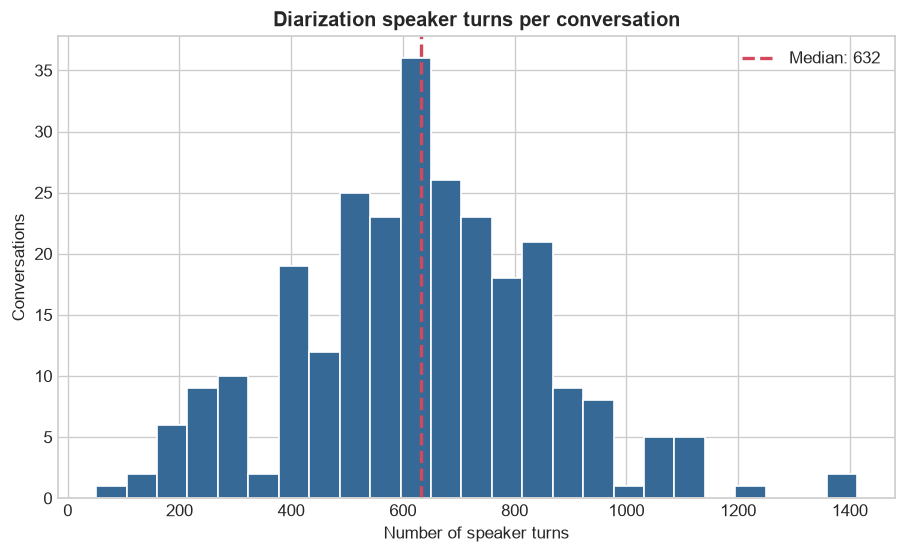

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(conversations.segment_count, bins=25, color="#376996", edgecolor="white")
median_segments = conversations.segment_count.median()
ax.axvline(median_segments, color="#d1495b", linestyle="--", linewidth=2, label=f"Median: {median_segments:,.0f}")
ax.set(title="Diarization speaker turns per conversation", xlabel="Number of speaker turns", ylabel="Conversations")
ax.legend()
plt.show()

## How many unique speakers are detected?

Counts refer to distinct anonymous labels within each conversation, not identified people. Diarization can split one person into several labels or merge similar voices.

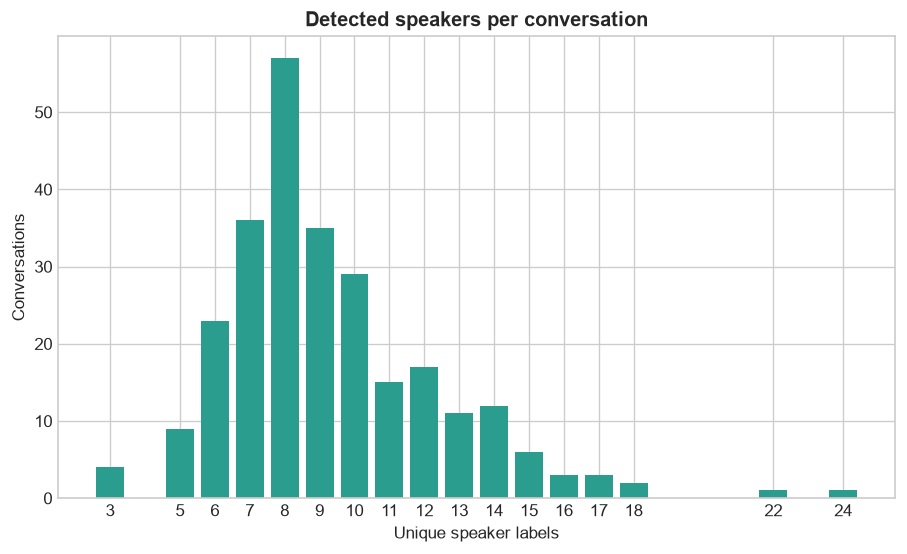

,conversations
unique_speakers,
3,4
5,9
6,23
7,36
8,57
9,35
10,29
11,15
12,17


In [5]:
speaker_counts = conversations.unique_speakers.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(speaker_counts.index, speaker_counts.values, color="#2a9d8f", width=0.8)
ax.set(title="Detected speakers per conversation", xlabel="Unique speaker labels", ylabel="Conversations")
ax.set_xticks(speaker_counts.index)
plt.show()
display(speaker_counts.rename("conversations").to_frame())

## How concentrated is speaking time?

The **dominant-speaker share** is the fraction of detected speech assigned to the most talkative speaker. The **normalized HHI** compares squared speaking shares with an equal-share conversation: 0 means equal speaking time and 1 means one speaker has all detected speech. **Gini** is another inequality measure, while the **effective speaker count** is the inverse HHI and answers roughly how many equally active speakers would produce the observed concentration.

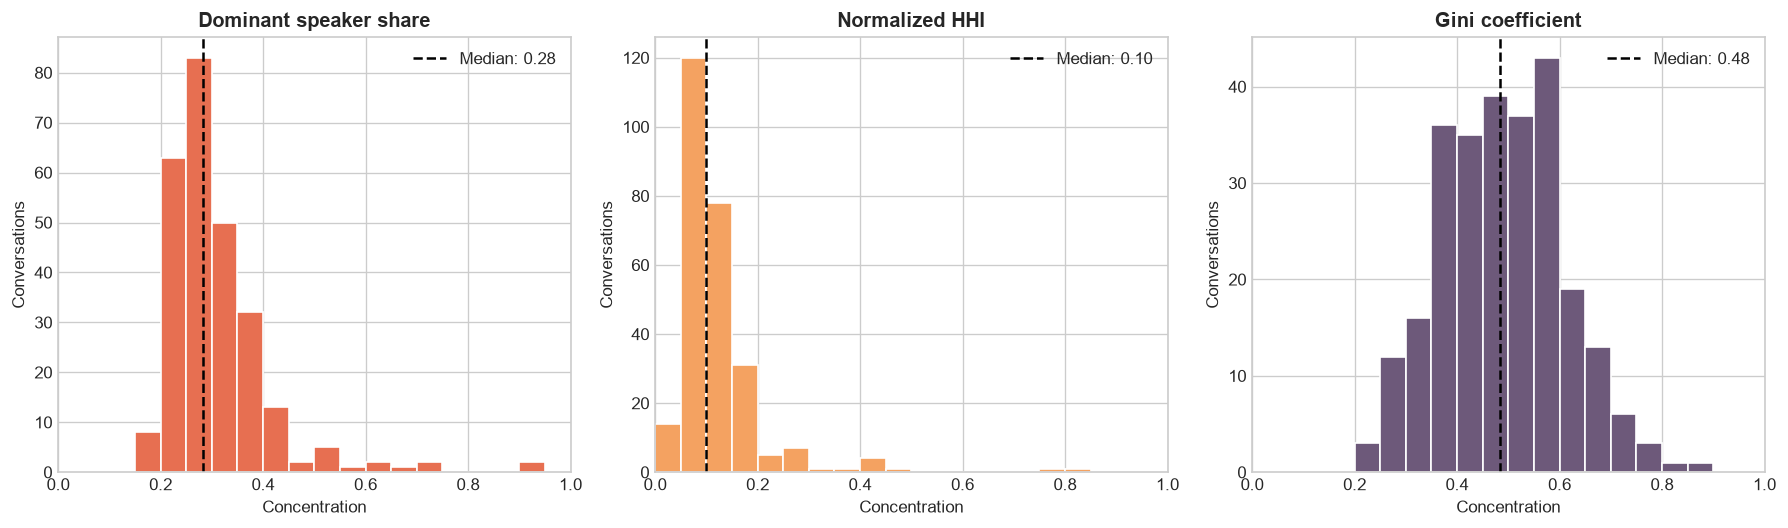

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plots = [
    ("dominant_speaker_share", "Dominant speaker share", "#e76f51"),
    ("normalized_hhi", "Normalized HHI", "#f4a261"),
    ("gini", "Gini coefficient", "#6d597a"),
]
for ax, (column, title, color) in zip(axes, plots, strict=True):
    values = conversations[column].dropna()
    ax.hist(values, bins=np.linspace(0, 1, 21), color=color, edgecolor="white")
    ax.axvline(values.median(), color="black", linestyle="--", label=f"Median: {values.median():.2f}")
    ax.set(title=title, xlabel="Concentration", ylabel="Conversations", xlim=(0, 1))
    ax.legend()
fig.tight_layout()
plt.show()

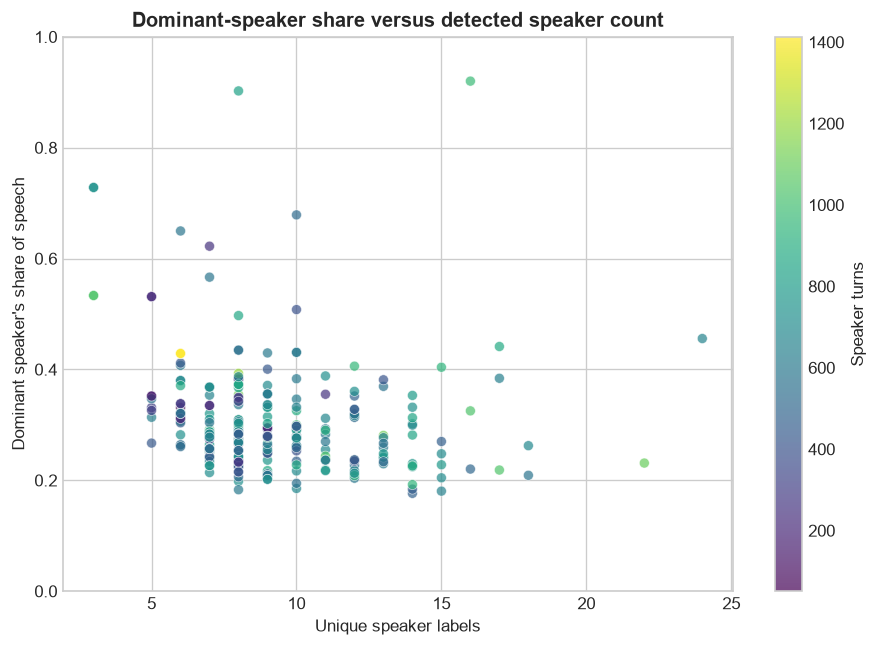

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(
    conversations.unique_speakers,
    conversations.dominant_speaker_share,
    c=conversations.segment_count,
    cmap="viridis",
    alpha=0.7,
    edgecolor="white",
    linewidth=0.4,
)
ax.set(title="Dominant-speaker share versus detected speaker count", xlabel="Unique speaker labels", ylabel="Dominant speaker's share of speech", ylim=(0, 1))
fig.colorbar(scatter, ax=ax, label="Speaker turns")
plt.show()

## Speaking shares by speaker rank

Speakers are ranked separately inside every conversation. Rank 1 is that conversation's most talkative detected speaker.

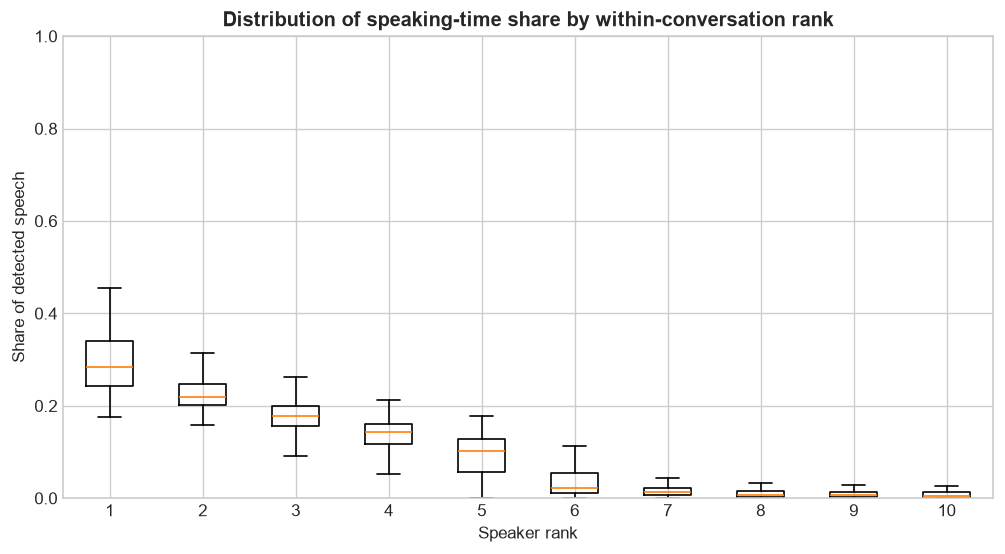

In [8]:
max_rank = min(10, int(speakers.speaker_rank.max()))
ranked_shares = [speakers.loc[speakers.speaker_rank.eq(rank), "speech_share"] for rank in range(1, max_rank + 1)]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(ranked_shares, tick_labels=range(1, max_rank + 1), showfliers=False)
ax.set(title="Distribution of speaking-time share by within-conversation rank", xlabel="Speaker rank", ylabel="Share of detected speech", ylim=(0, 1))
plt.show()

## Lorenz-style comparison of representative conversations

Curves farther below the equality diagonal indicate that speaking time is more concentrated among fewer speakers. The examples are selected by the 10th, 50th, and 90th percentiles of Gini among conversations with at least two detected speakers.

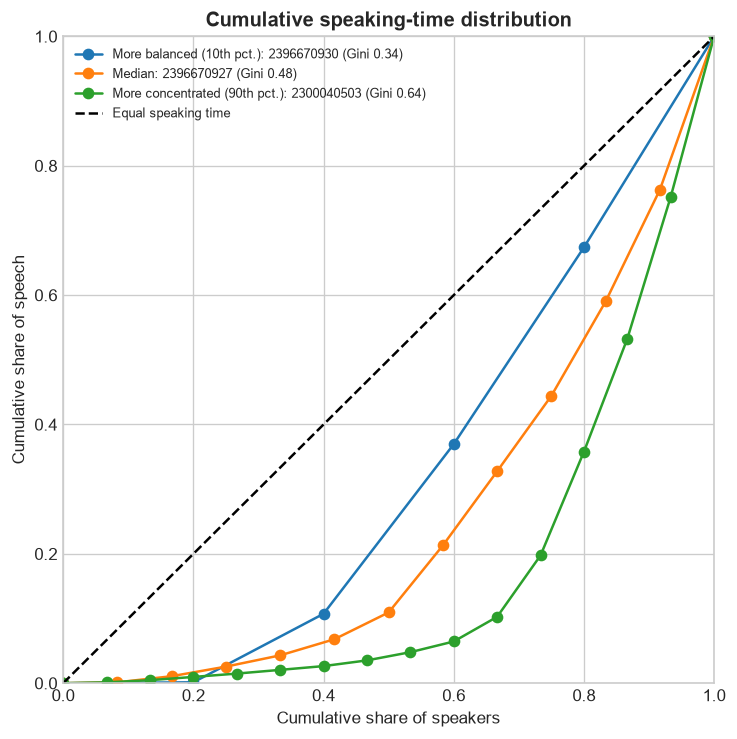

In [9]:
eligible = conversations.loc[conversations.unique_speakers.ge(2)].sort_values("gini").reset_index(drop=True)
positions = {"More balanced (10th pct.)": 0.10, "Median": 0.50, "More concentrated (90th pct.)": 0.90}
fig, ax = plt.subplots(figsize=(7, 7))
for label, quantile in positions.items():
    row = eligible.iloc[round(quantile * (len(eligible) - 1))]
    shares = speakers.loc[speakers.episode_id.eq(row.episode_id), "speech_share"].sort_values().to_numpy()
    cumulative_speakers = np.arange(len(shares) + 1) / len(shares)
    cumulative_speech = np.concatenate([[0], shares.cumsum()])
    ax.plot(cumulative_speakers, cumulative_speech, marker="o", label=f"{label}: {row.episode_id} (Gini {row.gini:.2f})")
ax.plot([0, 1], [0, 1], color="black", linestyle="--", label="Equal speaking time")
ax.set(title="Cumulative speaking-time distribution", xlabel="Cumulative share of speakers", ylabel="Cumulative share of speech", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=8)
plt.show()

## Conversations at the two ends of the concentration distribution

In [10]:
table_columns = [
    "episode_id", "segment_count", "unique_speakers",
    "dominant_speaker_share", "top_two_speaker_share",
    "normalized_hhi", "gini", "effective_speaker_count",
]
multi_speaker = conversations.loc[conversations.unique_speakers.ge(2)]
print("Most balanced by Gini")
display(multi_speaker.nsmallest(10, "gini")[table_columns])
print("Most concentrated by Gini")
display(multi_speaker.nlargest(10, "gini")[table_columns])

Most balanced by Gini


,episode_id,segment_count,unique_speakers,dominant_speaker_share,top_two_speaker_share,normalized_hhi,gini,effective_speaker_count
111,2323554809,427,5,0.267,0.522,0.062,0.223,4.005
105,2323554791,604,8,0.183,0.353,0.030,0.240,6.620
199,2397177240,722,7,0.227,0.426,0.036,0.241,5.755
50,2289585014,525,6,0.261,0.480,0.049,0.257,4.826
26,2267420987,539,6,0.263,0.481,0.050,0.260,4.803
33,2271676352,530,6,0.264,0.474,0.051,0.263,4.788
29,2267420996,730,8,0.198,0.372,0.035,0.266,6.440
68,2300040491,717,7,0.214,0.424,0.044,0.274,5.538
151,2395857129,825,7,0.227,0.452,0.043,0.275,5.569
161,2395991460,728,6,0.282,0.512,0.054,0.278,4.721


Most concentrated by Gini


,episode_id,segment_count,unique_speakers,dominant_speaker_share,top_two_speaker_share,normalized_hhi,gini,effective_speaker_count
239,2400184977,973,16,0.920,0.937,0.837,0.889,1.180
241,2400184983,838,8,0.902,0.926,0.790,0.801,1.225
233,2400164904,522,10,0.679,0.937,0.476,0.796,1.894
52,2289585020,668,24,0.456,0.657,0.235,0.787,3.750
136,2393585466,876,17,0.441,0.822,0.302,0.772,2.914
39,2277338243,1032,16,0.325,0.587,0.193,0.741,4.112
132,2387966373,244,7,0.622,0.946,0.409,0.722,2.027
124,2383011948,599,10,0.431,0.752,0.255,0.711,3.033
128,2383055904,599,10,0.431,0.752,0.255,0.711,3.033
10,2250797867,567,13,0.369,0.616,0.185,0.706,4.038


## Topic data and complete coverage

Topic labels come from the **combined Jev semantic assignment export**, not a year-specific subset. The assignments are joined to their original segment timing, then duplicate episode IDs are mapped to one canonical conversation. This gives topic coverage for all 264 diarization files while the comparisons use 219 unique conversations, preventing duplicate recordings from receiving extra weight.

Each conversation receives a primary high-level category and a primary detailed topic based on the greatest cumulative assigned segment duration. `primary_topic_share` records how much of the assigned duration belongs to that winner, because conversations usually contain several topics.

In [11]:
topic_root = project_root / "data/topic-analysis/results"
assignment_path = topic_root / "jev-semantic-all/assignments.parquet"
segment_path = topic_root / "segment-dataset/all-segments.parquet"
metadata_path = topic_root / "talk-metadata/talks.parquet"

assignments = pd.read_parquet(
    assignment_path,
    columns=[
        "segment_key", "jev_topic_id", "jev_topic_name",
        "jev_high_level_id", "jev_high_level_name",
    ],
)
segment_timing = pd.read_parquet(
    segment_path,
    columns=["segment_key", "episode_id", "start_seconds", "end_seconds", "text"],
)
meaningful_segment_mask = segment_timing.text.map(has_meaningful_text)
discarded_topic_segment_count = int((~meaningful_segment_mask).sum())
discarded_segment_keys = set(segment_timing.loc[~meaningful_segment_mask, "segment_key"])
segment_timing = segment_timing.loc[meaningful_segment_mask].copy()
assignments = assignments.loc[~assignments.segment_key.isin(discarded_segment_keys)].copy()
print(f"Discarded {discarded_topic_segment_count:,} empty/punctuation-only topic segments.")
topic_segments = assignments.merge(
    segment_timing, on="segment_key", how="left", validate="one_to_one"
)
if topic_segments.episode_id.isna().any():
    raise ValueError("Some topic assignments do not match the segment dataset")
topic_segments["episode_id"] = topic_segments.episode_id.astype(str)
topic_segments["duration_seconds"] = (
    topic_segments.end_seconds - topic_segments.start_seconds
).clip(lower=0)

talks = pd.read_parquet(
    metadata_path,
    columns=["episode_id", "duplicate_episode_ids", "title"],
)
alias_rows = [
    {
        "episode_id": str(alias),
        "canonical_episode_id": str(row.episode_id),
        "conversation_title": row.title,
    }
    for row in talks.itertuples()
    for alias in json.loads(row.duplicate_episode_ids)
]
episode_aliases = pd.DataFrame(alias_rows).drop_duplicates("episode_id")


def primary_topics(frame, id_column, name_column, prefix):
    rows = []
    for episode_id, group in frame.groupby("episode_id", sort=True):
        summary = primary_topic_summary(
            group.to_dict("records"),
            topic_id_key=id_column,
            topic_name_key=name_column,
        )
        rows.append({
            "canonical_episode_id": str(episode_id),
            f"primary_{prefix}_id": summary["primary_topic_id"],
            f"primary_{prefix}_name": summary["primary_topic_name"],
            f"primary_{prefix}_share": summary["primary_topic_share"],
            f"{prefix}_count": summary["topic_count"],
            f"{prefix}_assigned_seconds": summary["topic_duration_seconds"],
        })
    return pd.DataFrame(rows)


primary_high_level = primary_topics(
    topic_segments,
    "jev_high_level_id",
    "jev_high_level_name",
    "high_level",
)
primary_detailed = primary_topics(
    topic_segments,
    "jev_topic_id",
    "jev_topic_name",
    "detailed_topic",
)

conversations = (
    conversations.merge(episode_aliases, on="episode_id", how="left", validate="one_to_one")
    .merge(primary_high_level, on="canonical_episode_id", how="left", validate="many_to_one")
    .merge(primary_detailed, on="canonical_episode_id", how="left", validate="many_to_one")
)
if conversations.canonical_episode_id.isna().any():
    raise ValueError("Not every diarization episode maps to canonical talk metadata")
if conversations.primary_high_level_name.isna().any():
    raise ValueError("Not every canonical conversation has a high-level topic")
if conversations.primary_detailed_topic_name.isna().any():
    raise ValueError("Not every canonical conversation has a detailed topic")

conversations["is_canonical_episode"] = (
    conversations.episode_id == conversations.canonical_episode_id
)
canonical_conversations = (
    conversations.sort_values(
        ["canonical_episode_id", "is_canonical_episode"], ascending=[True, False]
    )
    .drop_duplicates("canonical_episode_id")
    .reset_index(drop=True)
)
canonical_conversations["segments_per_speech_hour"] = (
    canonical_conversations.segment_count
    / (canonical_conversations.total_speech_seconds / 3600)
)

assert len(conversations) == 264
assert len(canonical_conversations) == 219
print(
    f"Topic coverage: {conversations.primary_high_level_name.notna().sum()}/{len(conversations)} "
    "diarization files and "
    f"{canonical_conversations.primary_high_level_name.notna().sum()}/"
    f"{len(canonical_conversations)} canonical conversations."
)
print(
    f"{canonical_conversations.primary_high_level_name.nunique()} primary high-level "
    f"categories; {canonical_conversations.primary_detailed_topic_name.nunique()} "
    "primary detailed topics."
)

Discarded 0 empty/punctuation-only topic segments.


Topic coverage: 264/264 diarization files and 219/219 canonical conversations.
21 primary high-level categories; 189 primary detailed topics.


## Conversation distribution by primary high-level topic

The bar chart counts unique canonical conversations. “Unassigned” remains visible rather than being silently redistributed.

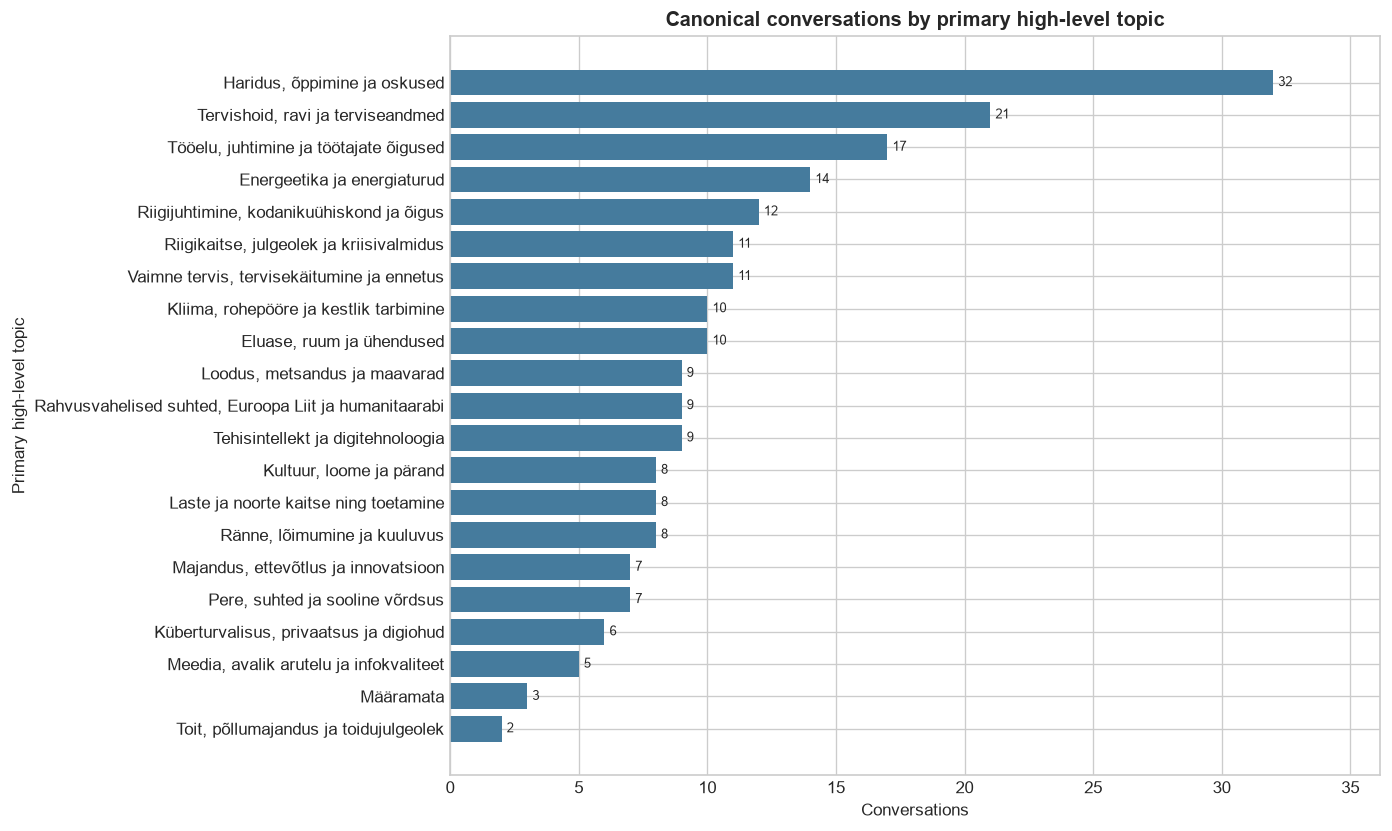

In [12]:
topic_counts = (
    canonical_conversations.primary_high_level_name.value_counts().sort_values()
)
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(topic_counts.index, topic_counts.values, color="#457b9d")
for index, value in enumerate(topic_counts.values):
    ax.text(value + 0.2, index, str(value), va="center", fontsize=8)
ax.set(
    title="Canonical conversations by primary high-level topic",
    xlabel="Conversations",
    ylabel="Primary high-level topic",
)
ax.set_xlim(0, topic_counts.max() * 1.13)
plt.show()

## Diarization distributions within topics

These boxplots preserve the full conversation-level distributions. Speaker-turn density is shown per detected speech hour so differences in recording length do not dominate that comparison.

C:\Users\risto\AppData\Local\Temp\ipykernel_46876\1311729571.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plot = ax.boxplot(
C:\Users\risto\AppData\Local\Temp\ipykernel_46876\1311729571.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plot = ax.boxplot(
C:\Users\risto\AppData\Local\Temp\ipykernel_46876\1311729571.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plot = ax.boxplot(


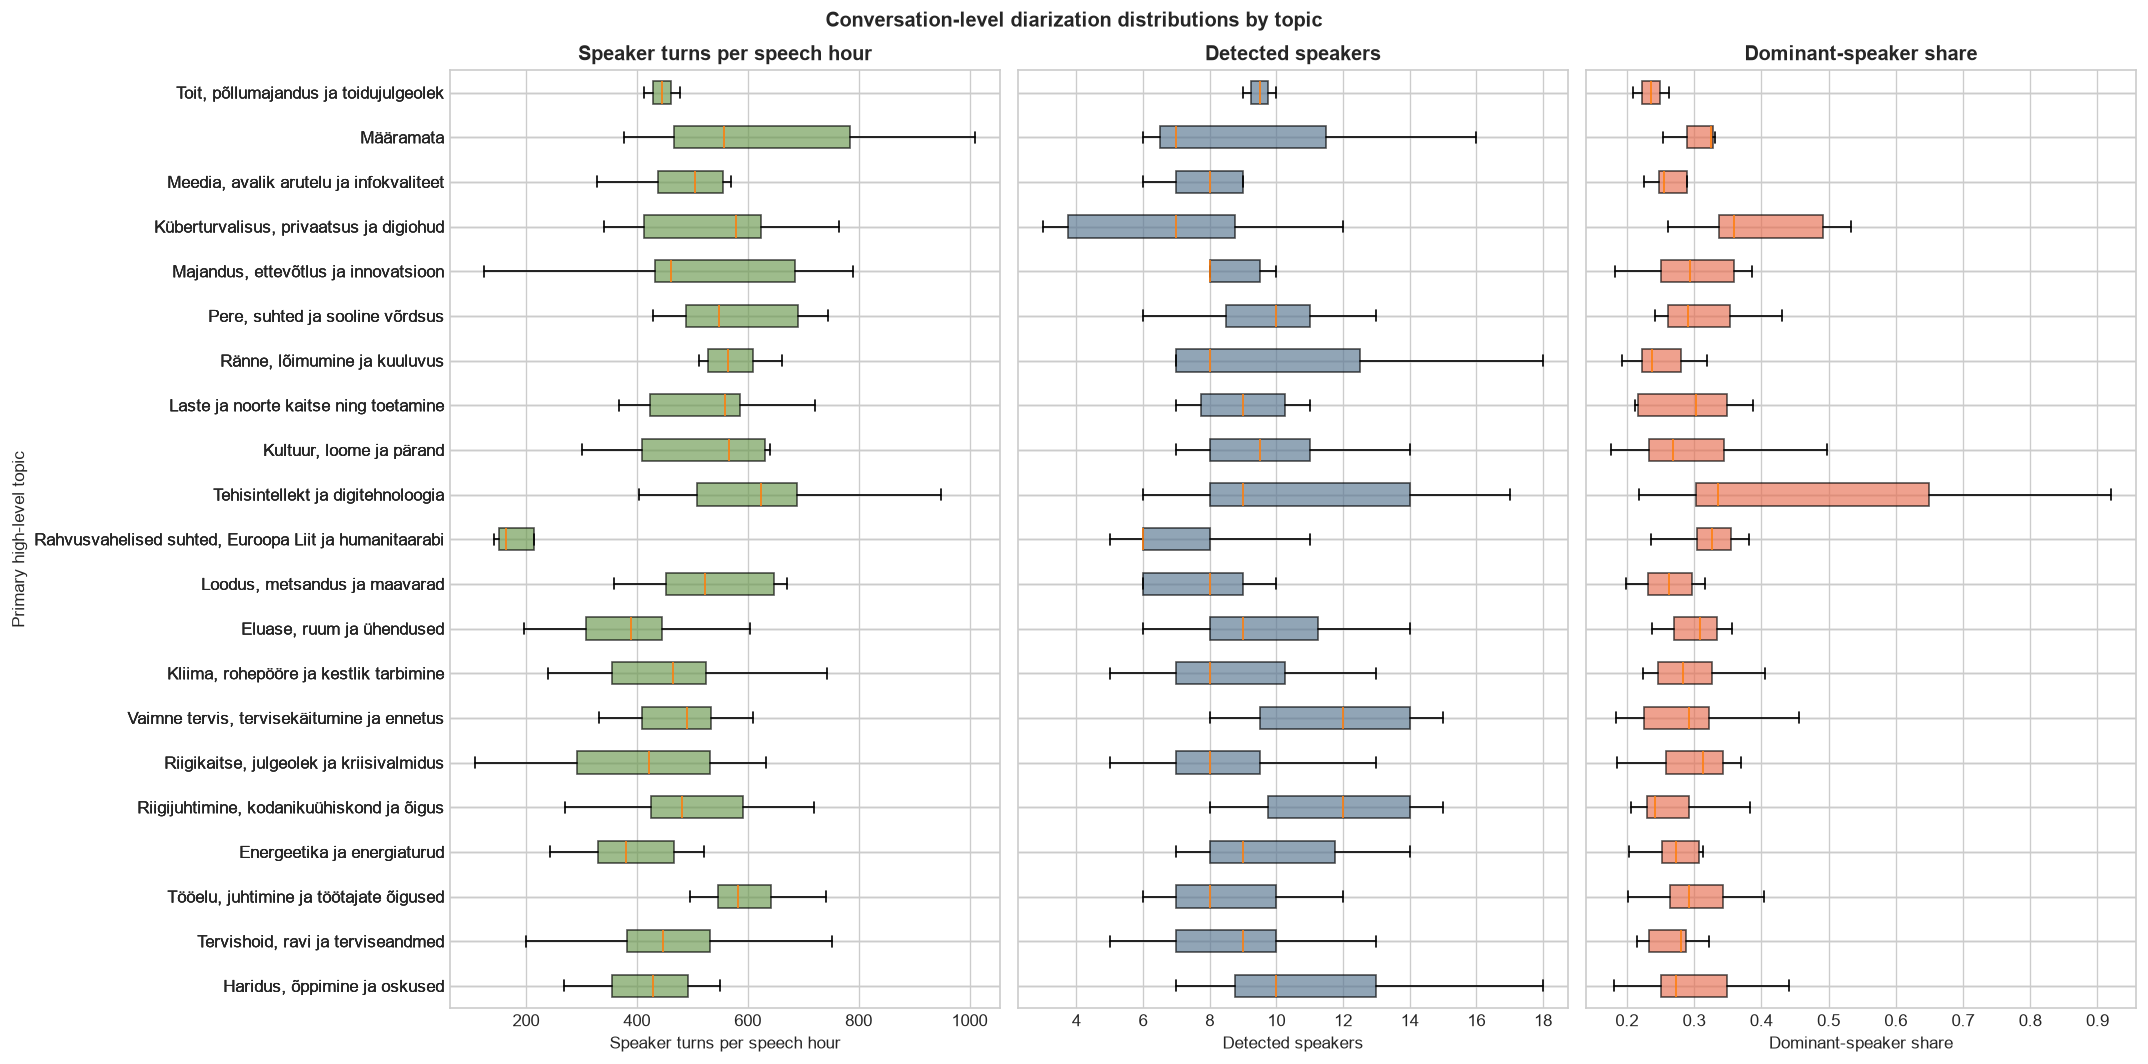

In [13]:
topic_order = topic_counts.sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 9), sharey=True)
distribution_specs = [
    ("segments_per_speech_hour", "Speaker turns per speech hour", "#6a994e"),
    ("unique_speakers", "Detected speakers", "#577590"),
    ("dominant_speaker_share", "Dominant-speaker share", "#e76f51"),
]
for ax, (column, title, color) in zip(axes, distribution_specs, strict=True):
    values = [
        canonical_conversations.loc[
            canonical_conversations.primary_high_level_name.eq(topic), column
        ].dropna()
        for topic in topic_order
    ]
    plot = ax.boxplot(
        values,
        vert=False,
        tick_labels=topic_order,
        showfliers=False,
        patch_artist=True,
    )
    for box in plot["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.65)
    ax.set(title=title, xlabel=title)
axes[0].set_ylabel("Primary high-level topic")
fig.suptitle("Conversation-level diarization distributions by topic", fontweight="bold")
fig.tight_layout()
plt.show()

## Median diarization profile by topic

Cell text contains the actual median. Color is standardized separately within each metric, so it highlights topics above or below that metric’s overall mean rather than comparing unlike units directly.

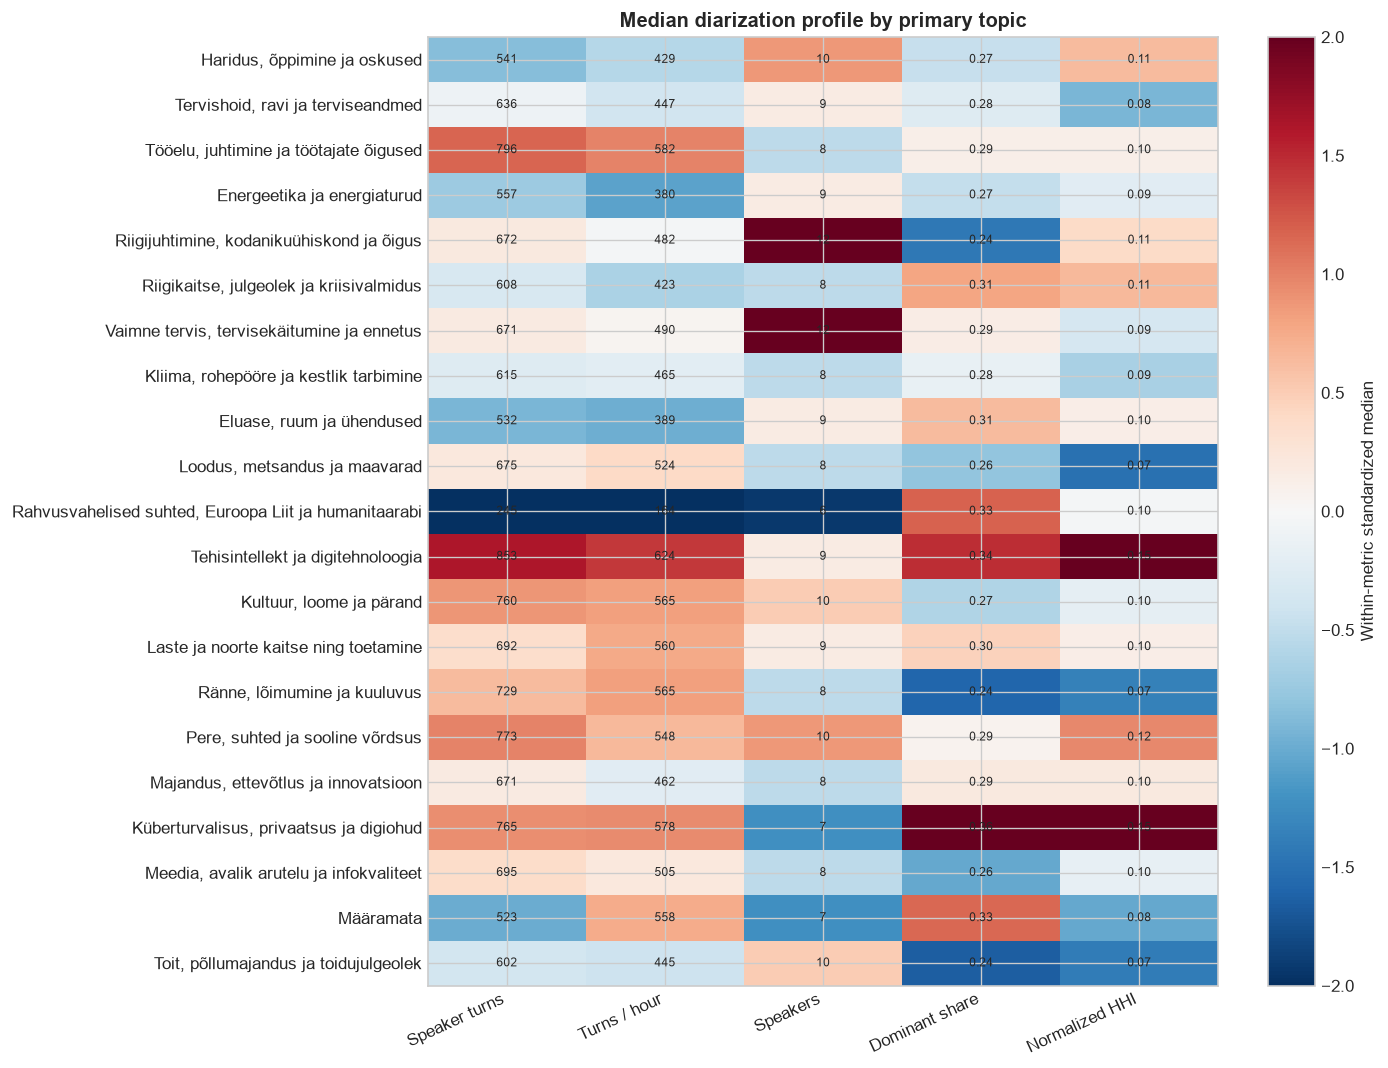

,segment_count,segments_per_speech_hour,unique_speakers,dominant_speaker_share,normalized_hhi
primary_high_level_name,,,,,
"Haridus, õppimine ja oskused",541.000,428.857,10.000,0.274,0.113
"Tervishoid, ravi ja terviseandmed",636.000,446.917,9.000,0.280,0.081
"Tööelu, juhtimine ja töötajate õigused",796.000,582.300,8.000,0.292,0.102
Energeetika ja energiaturud,557.000,380.184,9.000,0.273,0.095
"Riigijuhtimine, kodanikuühiskond ja õigus",672.500,481.604,12.000,0.242,0.107
"Riigikaitse, julgeolek ja kriisivalmidus",608.000,422.700,8.000,0.314,0.113
"Vaimne tervis, tervisekäitumine ja ennetus",671.000,489.828,12.000,0.293,0.093
"Kliima, rohepööre ja kestlik tarbimine",615.000,464.550,8.000,0.284,0.086
"Eluase, ruum ja ühendused",532.000,389.450,9.000,0.308,0.102


In [14]:
heatmap_columns = [
    "segment_count",
    "segments_per_speech_hour",
    "unique_speakers",
    "dominant_speaker_share",
    "normalized_hhi",
]
topic_medians = (
    canonical_conversations.groupby("primary_high_level_name")[heatmap_columns]
    .median()
    .loc[topic_order]
)
standardized = (topic_medians - topic_medians.mean()) / topic_medians.std(ddof=0)

fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(standardized, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_xticks(range(len(heatmap_columns)), [
    "Speaker turns", "Turns / hour", "Speakers", "Dominant share", "Normalized HHI"
], rotation=25, ha="right")
ax.set_yticks(range(len(topic_order)), topic_order)
for row in range(len(topic_order)):
    for column in range(len(heatmap_columns)):
        value = topic_medians.iloc[row, column]
        label = f"{value:.2f}" if column >= 3 else f"{value:.0f}"
        ax.text(column, row, label, ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Within-metric standardized median")
ax.set_title("Median diarization profile by primary topic")
fig.tight_layout()
plt.show()
display(topic_medians)

## Topic-mixture strength and detailed topics

The primary-topic share shows how dominant the winning category is inside each conversation. The detailed summary contains every primary detailed topic; the preview shows the 30 most common.

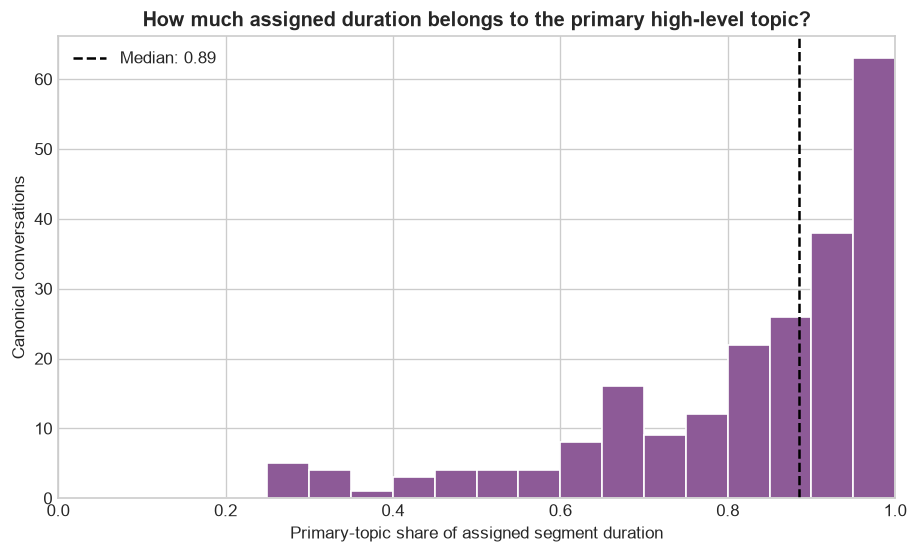

,conversations,median_segments,median_speakers,median_dominant_share,median_normalized_hhi,median_primary_topic_share
primary_detailed_topic_name,,,,,,
Juhitavate elektrivõimsuste vajadus Eestis,4,543.500,10.000,0.303,0.140,0.484
Patsiendi info jagamine ja koostöö,3,646.000,7.000,0.280,0.081,0.266
Unassigned,3,523.000,7.000,0.325,0.079,0.816
AI-agentide vastutus ja kontroll,2,730.000,11.500,0.371,0.189,0.610
AI-assistendi prompti ülesehitus,2,905.500,12.000,0.911,0.813,0.687
Alushariduse vastutus ja kvaliteet,2,530.000,10.000,0.227,0.076,0.864
Biogaasi ja vesiniku kasutus Eestis,2,557.000,9.500,0.242,0.081,0.571
Covidijärgne nakkushaiguste seaduse muutmine,2,538.000,8.500,0.242,0.086,0.333
Eesti 2050 ühised unistused ja tulevikunägemus,2,858.000,13.000,0.315,0.135,0.553


In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    canonical_conversations.primary_high_level_share,
    bins=np.linspace(0, 1, 21),
    color="#8d5a97",
    edgecolor="white",
)
ax.axvline(
    canonical_conversations.primary_high_level_share.median(),
    color="black",
    linestyle="--",
    label=f"Median: {canonical_conversations.primary_high_level_share.median():.2f}",
)
ax.set(
    title="How much assigned duration belongs to the primary high-level topic?",
    xlabel="Primary-topic share of assigned segment duration",
    ylabel="Canonical conversations",
    xlim=(0, 1),
)
ax.legend()
plt.show()

detailed_topic_summary = (
    canonical_conversations.groupby("primary_detailed_topic_name")
    .agg(
        conversations=("canonical_episode_id", "size"),
        median_segments=("segment_count", "median"),
        median_speakers=("unique_speakers", "median"),
        median_dominant_share=("dominant_speaker_share", "median"),
        median_normalized_hhi=("normalized_hhi", "median"),
        median_primary_topic_share=("primary_detailed_topic_share", "median"),
    )
    .sort_values(["conversations", "primary_detailed_topic_name"], ascending=[False, True])
)
display(detailed_topic_summary.head(30))

## Interpretation notes

- These statistics describe **model output**, not ground-truth participation. Speaker-count and concentration errors can result from speaker splitting, speaker merging, music, applause, or background voices.
- Duration is summed across turns. If overlapping speech is represented by overlapping turns, total detected speech can exceed the recording's wall-clock speaking span. Shares still sum to one across detected speakers.
- Very short turns can indicate rapid exchanges, but they can also be boundary artifacts. The quality table makes their prevalence visible without silently filtering them.
- Comparing concentration across conversations is most meaningful when recording conditions and diarization settings are similar.